# Phân tích Thành phần Chính (PCA) & Phân rã Giá trị Đặc dị (SVD)

Mục tiêu của PCA là chiếu (project) dữ liệu từ không gian nhiều chiều ($D$) xuống một không gian ít chiều hơn ($K$) sao cho **bảo toàn được nhiều phương sai (thông tin) nhất có thể**.

**1. Ma trận Hiệp phương sai (Covariance Matrix):**
Đầu tiên, dữ liệu $X$ bắt buộc phải được chuẩn hóa về tâm $0$ (Mean Centering).
Ma trận hiệp phương sai $\Sigma$ kích thước $D \times D$ đo lường sự biến thiên cùng nhau giữa các cặp đặc trưng:
$$\Sigma = \frac{1}{N-1} X^T X$$

**2. Trị riêng (Eigenvalues) và Vector riêng (Eigenvectors):**
Giải phương trình đặc trưng của ma trận $\Sigma$:
$$\Sigma v = \lambda v$$
*   **Vector riêng ($v$):** Chỉ ra "hướng" phân tán của dữ liệu (Các thành phần chính - Principal Components).
*   **Trị riêng ($\lambda$):** Thể hiện độ lớn (phương sai) mà hướng đó nắm giữ. 

**3. Phân rã SVD (Singular Value Decomposition):**
Thay vì tính ma trận Hiệp phương sai $\Sigma$ (có thể gây mất mát độ chính xác số học nếu tính $X^T X$), các thư viện thực tế như Sklearn sử dụng SVD trực tiếp trên ma trận $X$:
$$X = U S V^T$$
Lúc này, các hàng của $V^T$ chính là các Vector riêng, và bình phương các phần tử của $S$ tỷ lệ thuận với các Trị riêng. 

*Trong bài này, chúng ta sẽ lập trình cách tiếp cận cổ điển: Eigendecomposition trên Covariance Matrix để dễ hiểu nhất về mặt hình học.*

In [1]:
import numpy as np

class PCAScratch:
    """Phân tích thành phần chính (PCA) sử dụng Phân rã Trị riêng."""
    def __init__(self, n_components: int):
        self.n_components = n_components
        self.components = None
        self.mean = None
        self.explained_variance_ratio_ = None

    def fit(self, X: np.ndarray):
        X = np.asarray(X)
        
        # 1. Dời tâm dữ liệu về 0 (Mean Centering)
        self.mean = np.mean(X, axis=0)
        X_centered = X - self.mean

        # 2. Tính ma trận Hiệp phương sai (Covariance Matrix)
        # Sử dụng rowvar=False vì mỗi cột là 1 đặc trưng (feature)
        cov_matrix = np.cov(X_centered, rowvar=False)

        # 3. Phân rã Trị riêng (Eigendecomposition)
        # eigh tối ưu và ổn định hơn eig đối với ma trận đối xứng (như cov_matrix)
        eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

        # 4. Sắp xếp các vector riêng theo trị riêng giảm dần
        # np.linalg.eigh trả về trị riêng tăng dần, nên ta phải đảo ngược [::-1]
        sorted_idxs = np.argsort(eigenvalues)[::-1]
        eigenvalues = eigenvalues[sorted_idxs]
        eigenvectors = eigenvectors[:, sorted_idxs]

        # 5. Lưu lại K Vector riêng (Thành phần chính) đầu tiên
        self.components = eigenvectors[:, :self.n_components]
        
        # 6. Tính tỷ lệ phương sai được giải thích (Đánh giá chất lượng nén)
        total_variance = np.sum(eigenvalues)
        self.explained_variance_ratio_ = eigenvalues[:self.n_components] / total_variance
        
        return self

    def transform(self, X: np.ndarray) -> np.ndarray:
        # Chiếu (Project) dữ liệu gốc xuống không gian mới K-chiều
        X_centered = np.asarray(X) - self.mean
        return np.dot(X_centered, self.components)
        
    def fit_transform(self, X: np.ndarray) -> np.ndarray:
        return self.fit(X).transform(X)

Metric                    | Scratch         | Sklearn        
------------------------------------------------------------
Time (ms)                 | 0.00            | 0.00           
Thông tin giữ lại (%)     | 99.34           | 99.34          


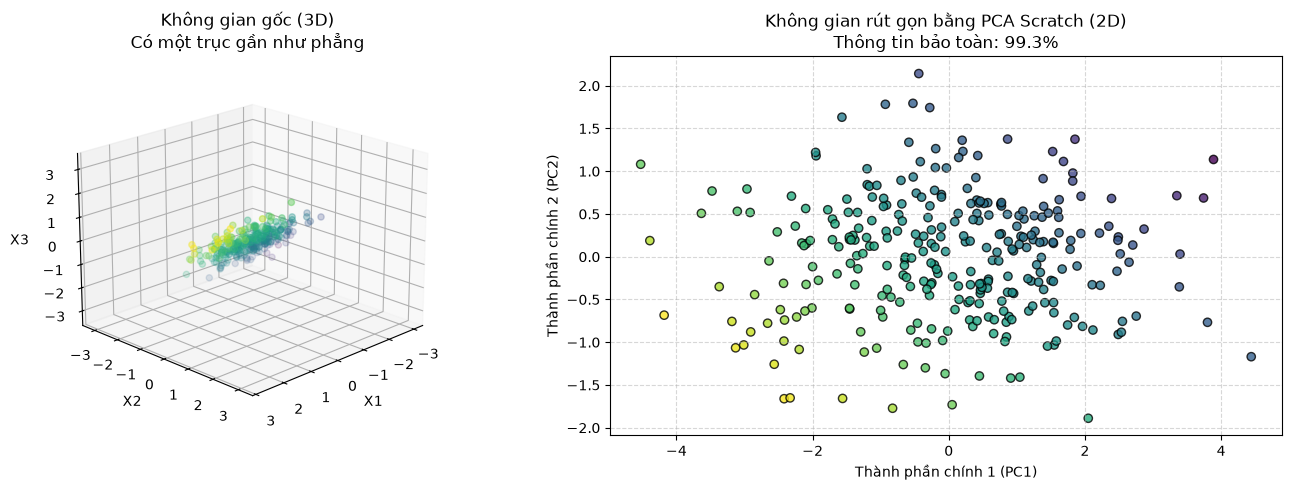

In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from utils.preprocessing import StandardScaler

# 1. Sinh dữ liệu 3 chiều (3D) nhân tạo
np.random.seed(42)
# Sinh 300 điểm ngẫu nhiên trong không gian 3D
X_3D = np.random.randn(300, 3)
# Cố tình kéo dãn dữ liệu theo một mặt phẳng để tạo ra các "Thành phần chính" rõ nét
transformation = np.array([[1.5, 0.5, 0.2], 
                           [0.5, 2.0, 0.5], 
                           [0.0, 0.0, 0.1]]) # Trục Z bị nén bẹp (nhiễu)
X_3D = np.dot(X_3D, transformation)

# Gán màu sắc giả định dựa trên tọa độ X ban đầu để dễ theo dõi sau khi nén
y_color = X_3D[:, 0]

# PCA cực kỳ nhạy cảm với thang đo, BẮT BUỘC phải Scale
scaler = StandardScaler()
X_3D_scaled = scaler.fit_transform(X_3D)

# 2. Chạy model Scratch (Nén 3D -> 2D)
t0 = time.time()
pca_scratch = PCAScratch(n_components=2).fit(X_3D_scaled)
X_2D_scratch = pca_scratch.transform(X_3D_scaled)
t_scratch = (time.time() - t0) * 1000

# 3. Chạy model Sklearn (Sử dụng thuật toán SVD)
t0 = time.time()
pca_sklearn = PCA(n_components=2, random_state=42).fit(X_3D_scaled)
X_2D_sklearn = pca_sklearn.transform(X_3D_scaled)
t_sklearn = (time.time() - t0) * 1000

print(f"{'Metric':<25} | {'Scratch':<15} | {'Sklearn':<15}")
print("-" * 60)
print(f"{'Time (ms)':<25} | {t_scratch:<15.2f} | {t_sklearn:<15.2f}")
# In ra phần trăm thông tin giữ lại được
evr_scratch = np.sum(pca_scratch.explained_variance_ratio_) * 100
evr_sklearn = np.sum(pca_sklearn.explained_variance_ratio_) * 100
print(f"{'Thông tin giữ lại (%)':<25} | {evr_scratch:<15.2f} | {evr_sklearn:<15.2f}")

# 4. Trực quan hóa quá trình nén (3D -> 2D)
fig = plt.figure(figsize=(14, 5))

# Đồ thị 1: Dữ liệu gốc 3D
ax1 = fig.add_subplot(121, projection='3d')
ax1.scatter(X_3D_scaled[:, 0], X_3D_scaled[:, 1], X_3D_scaled[:, 2], c=y_color, cmap='viridis', alpha=0.7)
ax1.set_title("Không gian gốc (3D)\nCó một trục gần như phẳng")
ax1.set_xlabel("X1")
ax1.set_ylabel("X2")
ax1.set_zlabel("X3")
ax1.view_init(elev=20, azim=45)

# Đồ thị 2: Dữ liệu sau khi nén bằng PCA (2D)
ax2 = fig.add_subplot(122)
# Lưu ý: Các vector riêng của Scratch và Sklearn có thể ngược dấu nhau (chỉ khác chiều, cùng phương),
# dẫn đến đồ thị có thể bị lật đối xứng (flipped). Điều này hoàn toàn hợp lệ trong toán học.
ax2.scatter(X_2D_scratch[:, 0], X_2D_scratch[:, 1], c=y_color, cmap='viridis', edgecolors='k', alpha=0.8)
ax2.set_title(f"Không gian rút gọn bằng PCA Scratch (2D)\nThông tin bảo toàn: {evr_scratch:.1f}%")
ax2.set_xlabel("Thành phần chính 1 (PC1)")
ax2.set_ylabel("Thành phần chính 2 (PC2)")
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()